In [46]:
import pandas as pd

life = pd.read_csv("../data/raw/life_expectancy.csv", skiprows=4)
print(life.shape)
life.head()

(266, 71)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,64.049000,64.215000,64.602000,64.944000,65.303000,65.615000,...,75.620000,75.880000,76.019000,75.406000,73.655000,76.226000,76.353000,76.500000,NaN,NaN
1,Africa Eastern and Southern,AFE,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,44.169658,44.468838,44.877890,45.160583,45.535695,45.770723,...,62.591275,63.330691,63.857261,63.766484,62.979999,64.487152,65.146228,65.349930,NaN,NaN
2,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,32.799000,33.291000,33.757000,34.201000,34.673000,35.124000,...,62.406000,62.443000,62.941000,61.454000,60.417000,65.617000,66.035000,66.289000,NaN,NaN
3,Africa Western and Central,AFW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,37.779636,38.058973,38.681792,38.936918,39.194375,39.478875,...,56.620764,57.030771,57.142827,57.357709,57.355015,57.978995,58.847483,59.041538,NaN,NaN
4,Angola,AGO,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,37.933000,36.902000,37.168000,37.419000,37.704000,37.968000,...,62.122000,62.622000,63.051000,63.116000,62.958000,64.246000,64.617000,64.805000,NaN,NaN


In [47]:
meta = pd.read_csv("../data/raw/country_metadata.csv")
print(meta.columns.tolist())
meta.shape

['Country Code', 'Region', 'IncomeGroup', 'SpecialNotes', 'TableName', 'Unnamed: 5']


(265, 6)

In [49]:
meta["Region"].value_counts(dropna=False)

Region
Europe & Central Asia         58
NaN                           48
Sub-Saharan Africa            48
Latin America & Caribbean     42
East Asia & Pacific           37
Middle East & North Africa    23
South Asia                     6
North America                  3
Name: count, dtype: int64

### Cell 1: drop the junk columns

In [50]:
life = life.loc[:, ~life.columns.str.startswith("Unnamed")]
meta = meta.loc[:, ~meta.columns.str.startswith("Unnamed")]

print(life.shape, meta.shape)

(266, 70) (265, 5)


### Cell 2: find the mismatched row

In [51]:
merged = life.merge(meta, on="Country Code", how="outer", indicator=True)
print(merged["_merge"].value_counts())
merged[merged["_merge"] != "both"][["Country Name", "Country Code", "_merge"]]

_merge
both          265
left_only       1
right_only      0
Name: count, dtype: int64


,Country Name,Country Code,_merge
110,Not classified,INX,left_only


### Cell 3: keep Sub-Saharan Africa only

In [52]:
africa = merged[merged["Region"] == "Sub-Saharan Africa"].copy()
print(africa.shape)
africa[["Country Name", "Country Code", "2019"]].head(10)

(48, 75)


,Country Name,Country Code,2019
4,Angola,AGO,63.051
16,Burundi,BDI,62.180
18,Benin,BEN,59.888
19,Burkina Faso,BFA,60.184
33,Botswana,BWA,67.167
34,Central African Republic,CAF,31.530
41,Cote d'Ivoire,CIV,60.274
42,Cameroon,CMR,61.695
43,"Congo, Dem. Rep.",COD,60.242
44,"Congo, Rep.",COG,63.152


### Cell 4: check missing values and find Kenya

In [53]:
print("Missing in 2019:", africa["2019"].isna().sum())
africa[africa["Country Name"] == "Kenya"][["Country Name", "2019"]]

Missing in 2019: 0


,Country Name,2019
121,Kenya,62.939


In [54]:
year_cols = [str(y) for y in range(2012, 2025)]
caf = africa[africa["Country Code"] == "CAF"][["Country Name"] + year_cols]
caf.T

,34
Country Name,Central African Republic
2012,51.336
2013,49.487
2014,40.265
2015,51.934
2016,50.999
2017,45.231
2018,52.297
2019,31.53
2020,50.596


In [55]:
africa.sort_values("2019")[["Country Name", "2019"]].head(5)

,Country Name,2019
34,Central African Republic,31.530
229,Chad,52.993
174,Nigeria,53.009
141,Lesotho,55.249
213,"Somalia, Fed. Rep.",57.249


### Cell A: loading the new data and join it to our 48 countries

In [56]:
wdi = pd.read_csv("../data/raw/wdi_2019.csv")
ssa = meta[meta["Region"] == "Sub-Saharan Africa"][["Country Code", "TableName", "IncomeGroup"]]
data = ssa.merge(wdi, on="Country Code", how="left")
print(data.shape)
data.isna().sum()

(48, 11)


Country Code                    0
TableName                       0
IncomeGroup                     0
life_expectancy                 0
gdp_per_capita                  2
health_spending_pct_gdp         0
electricity_access              0
basic_water                     2
basic_sanitation                2
female_secondary_enrollment    29
urban_population_pct            0
dtype: int64

### Cell B: checking the API data matches the CSV we downloaded by hand

In [57]:
data[data["Country Code"].isin(["CAF", "KEN"])]

,Country Code,TableName,IncomeGroup,life_expectancy,gdp_per_capita,health_spending_pct_gdp,electricity_access,basic_water,basic_sanitation,female_secondary_enrollment,urban_population_pct
5,CAF,Central African Republic,Low income,31.530,449.228468,7.760815,14.3,38.212266,14.481982,NaN,41.780043
20,KEN,Kenya,Lower middle income,62.939,1960.408089,4.368747,69.7,61.490764,37.298798,NaN,31.189557


### Cell C: seeing the ranges of every variable

In [58]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
life_expectancy,48.0,62.583608,6.535703,31.530000,60.145750,62.926500,66.023000,75.449000
gdp_per_capita,46.0,2516.031297,3438.939947,234.310616,772.008120,1106.439211,2412.983057,19141.511874
health_spending_pct_gdp,48.0,5.304498,3.150478,2.203943,3.251596,4.547493,6.184003,21.923731
electricity_access,48.0,49.872917,25.075009,6.800000,30.975000,47.800000,68.875000,100.000000
basic_water,46.0,68.453248,15.390750,35.687894,58.885333,68.122008,78.681849,99.805201
basic_sanitation,46.0,39.489600,21.698864,8.684740,21.740756,37.105552,49.687188,98.885831
female_secondary_enrollment,19.0,58.701762,27.859372,14.196713,39.045548,47.612283,77.725392,107.597072
urban_population_pct,48.0,43.232311,16.900685,16.138375,30.968342,42.240944,54.392751,89.903185


### Cell D: which countries have missing values?

In [59]:
cols = ["gdp_per_capita", "basic_water", "basic_sanitation"]
data[data[cols].isna().any(axis=1)][["TableName"] + cols]

,TableName,gdp_per_capita,basic_water,basic_sanitation
12,Eritrea,NaN,NaN,NaN
19,Equatorial Guinea,6804.149231,NaN,NaN
37,South Sudan,NaN,39.913624,12.537598


### Cell E: rechecking Kenya and the Central African Republic, showing only the useful columns

In [60]:
data[data["Country Code"].isin(["CAF", "KEN"])][["TableName", "life_expectancy", "gdp_per_capita", "electricity_access"]]

,TableName,life_expectancy,gdp_per_capita,electricity_access
5,Central African Republic,31.530,449.228468,14.3
20,Kenya,62.939,1960.408089,69.7


### Cell F: minimum and maximum of every variable

In [61]:
data.describe().T[["min", "max"]]

,min,max
life_expectancy,31.530000,75.449000
gdp_per_capita,234.310616,19141.511874
health_spending_pct_gdp,2.203943,21.923731
electricity_access,6.800000,100.000000
basic_water,35.687894,99.805201
basic_sanitation,8.684740,98.885831
female_secondary_enrollment,14.196713,107.597072
urban_population_pct,16.138375,89.903185


### Cell G: looking at the shapes

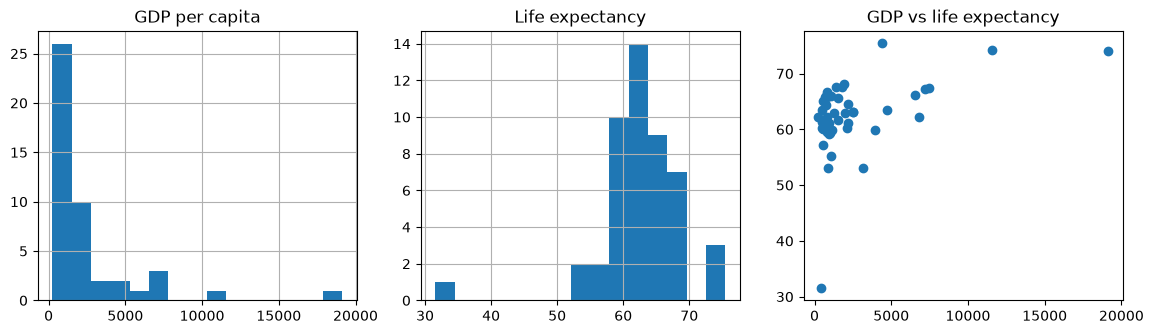

In [62]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
data["gdp_per_capita"].hist(ax=ax[0], bins=15)
ax[0].set_title("GDP per capita")
data["life_expectancy"].hist(ax=ax[1], bins=15)
ax[1].set_title("Life expectancy")
ax[2].scatter(data["gdp_per_capita"], data["life_expectancy"])
ax[2].set_title("GDP vs life expectancy")
plt.show()